In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hurricane_df = pd.read_csv(
    "../../data/disaster_data/us_landfall_hurricanes_hurdat.csv"
)

market_df = pd.read_csv(
    "../../data/stock_data/market_raw.csv"
)

hurricane_df["landfall_time"] = pd.to_datetime(
    hurricane_df["landfall_time"]
)

market_df["Date"] = pd.to_datetime(market_df["Date"])

market_df = (
    market_df
    .sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)

sectors = ["XLE", "XLF", "XLI", "XLU"]

sector_names = {
    "XLE": "Energy",
    "XLF": "Financials",
    "XLI": "Industrials",
    "XLU": "Utilities"
}

In [2]:
N = 10

top_n = (
    hurricane_df
    .dropna(subset=[
        "landfall_wind_kts",
        "landfall_time"
    ])
    .sort_values(
        ["landfall_wind_kts",
         "landfall_pressure_mb",
         "storm_id"],
        ascending=[False, True, True]
    )
    .head(N)
    .copy()
)

display(top_n[
    ["hurricane_name", "season",
     "landfall_wind_kts", "landfall_time"]
])

,hurricane_name,season,landfall_wind_kts,landfall_time
27,Michael (2018),2018,140.0,2018-10-10 17:30:00
36,Ida (2021),2021,130.0,2021-08-29 16:55:00
32,Laura (2020),2020,130.0,2020-08-27 06:00:00
3,Charley (2004),2004,130.0,2004-08-13 19:45:00
38,Ian (2022),2022,130.0,2022-09-28 19:05:00
44,Helene (2024),2024,120.0,2024-09-27 03:10:00
24,Irma (2017),2017,115.0,2017-09-10 13:00:00
23,Harvey (2017),2017,115.0,2017-08-26 03:00:00
10,Katrina (2005),2005,110.0,2005-08-29 11:10:00
6,Ivan (2004),2004,105.0,2004-09-16 06:50:00


In [3]:
for sector in sectors:
    market_df[f"{sector}_Return"] = (
        market_df[f"{sector}_Close"]
        .pct_change(fill_method=None) * 100
    )

display(market_df[
    ["Date"] + [f"{s}_Return" for s in sectors]
].head(10))

,Date,XLE_Return,XLF_Return,XLI_Return,XLU_Return
0,1999-11-24,NaN,NaN,NaN,NaN
1,1999-11-26,-1.469005,-0.693181,-0.498093,1.147644
2,1999-11-29,-0.802693,-2.411130,-1.668545,-1.134623
3,1999-11-30,-0.173430,1.690458,-0.452494,1.256923
4,1999-12-01,1.968708,-0.767216,0.795425,0.485652
5,1999-12-02,-0.965377,0.450945,-0.225493,-0.590705
6,1999-12-03,-0.458675,2.373393,1.638429,1.944881
7,1999-12-06,-0.057603,-2.694194,-0.277895,-0.688954
8,1999-12-07,-1.901980,-0.193254,-1.895211,0.747102
9,1999-12-08,1.057494,-2.387051,1.761381,-0.794485


In [4]:
trading_dates = pd.DatetimeIndex(market_df["Date"])

def get_event_date(landfall_time):

    if pd.isna(landfall_time):
        return pd.NaT

    idx = trading_dates.searchsorted(
        landfall_time.normalize(),
        side="left"
    )

    if idx >= len(trading_dates):
        return pd.NaT

    return trading_dates[idx]

top_n["event_date"] = (
    top_n["landfall_time"].apply(get_event_date)
)

display(top_n[
    ["hurricane_name", "landfall_time", "event_date"]
])

,hurricane_name,landfall_time,event_date
27,Michael (2018),2018-10-10 17:30:00,2018-10-10
36,Ida (2021),2021-08-29 16:55:00,2021-08-30
32,Laura (2020),2020-08-27 06:00:00,2020-08-27
3,Charley (2004),2004-08-13 19:45:00,2004-08-13
38,Ian (2022),2022-09-28 19:05:00,2022-09-28
44,Helene (2024),2024-09-27 03:10:00,2024-09-27
24,Irma (2017),2017-09-10 13:00:00,2017-09-11
23,Harvey (2017),2017-08-26 03:00:00,2017-08-28
10,Katrina (2005),2005-08-29 11:10:00,2005-08-29
6,Ivan (2004),2004-09-16 06:50:00,2004-09-16


In [5]:
event_rows = []

for _, storm in top_n.iterrows():

    event_date = storm["event_date"]

    if pd.isna(event_date):
        continue

    matches = market_df.index[
        market_df["Date"] == event_date
    ]

    if len(matches) == 0:
        continue

    event_idx = matches[0]

    if event_idx < 5 or event_idx + 14 >= len(market_df):
        continue

    window = market_df.iloc[
        event_idx - 5 : event_idx + 15
    ].copy()

    window["relative_day"] = np.arange(-5, 15)

    for sector in sectors:

        if window[f"{sector}_Return"].isna().any():
            continue

        for _, row in window.iterrows():

            event_rows.append({
                "storm_id": storm["storm_id"],
                "hurricane": storm["hurricane_name"],
                "year": storm["season"],
                "sector": sector,
                "Date": row["Date"],
                "relative_day": row["relative_day"],
                "daily_return": row[f"{sector}_Return"]
            })

event_study = pd.DataFrame(event_rows)

event_study = event_study.sort_values(
    ["storm_id", "sector", "relative_day"]
)

event_study["cumulative_return"] = (
    (
        1 + event_study["daily_return"] / 100
    )
    .groupby([
        event_study["storm_id"],
        event_study["sector"]
    ])
    .cumprod()
    .sub(1)
    .mul(100)
)

display(event_study.head(10))

,storm_id,hurricane,year,sector,Date,relative_day,daily_return,cumulative_return
240,2004223N11301,Charley (2004),2004,XLE,2004-08-06,-5,-1.996175,-1.996175
241,2004223N11301,Charley (2004),2004,XLE,2004-08-09,-4,1.616503,-0.411940
242,2004223N11301,Charley (2004),2004,XLE,2004-08-10,-3,-0.381790,-0.792157
243,2004223N11301,Charley (2004),2004,XLE,2004-08-11,-2,-0.511011,-1.299120
244,2004223N11301,Charley (2004),2004,XLE,2004-08-12,-1,-1.284056,-2.566495
245,2004223N11301,Charley (2004),2004,XLE,2004-08-13,0,1.235745,-1.362465
246,2004223N11301,Charley (2004),2004,XLE,2004-08-16,1,0.610313,-0.760467
247,2004223N11301,Charley (2004),2004,XLE,2004-08-17,2,-2.298828,-3.041813
248,2004223N11301,Charley (2004),2004,XLE,2004-08-18,3,1.307170,-1.774405
249,2004223N11301,Charley (2004),2004,XLE,2004-08-19,4,0.322596,-1.457533


In [6]:
windows = {
    "0_to_1": (0, 1),
    "0_to_5": (0, 5),
    "0_to_14": (0, 14)
}

return_rows = []

for (storm_id, sector), group in event_study.groupby(
    ["storm_id", "sector"]
):

    for window_name, (start, end) in windows.items():

        selected = group[
            group["relative_day"].between(start, end)
        ]

        if len(selected) != end - start + 1:
            continue

        cumulative_return = (
            (1 + selected["daily_return"] / 100).prod() - 1
        ) * 100

        return_rows.append({
            "storm_id": storm_id,
            "hurricane": group["hurricane"].iloc[0],
            "year": group["year"].iloc[0],
            "sector": sector,
            "window": window_name,
            "return_pct": cumulative_return
        })

returns_df = pd.DataFrame(return_rows)

display(returns_df.head(12))

,storm_id,hurricane,year,sector,window,return_pct
0,2004223N11301,Charley (2004),2004,XLE,0_to_1,1.853600
1,2004223N11301,Charley (2004),2004,XLE,0_to_5,2.178818
2,2004223N11301,Charley (2004),2004,XLE,0_to_14,6.569070
3,2004223N11301,Charley (2004),2004,XLF,0_to_1,1.637482
4,2004223N11301,Charley (2004),2004,XLF,0_to_5,4.075719
5,2004223N11301,Charley (2004),2004,XLF,0_to_14,5.858778
6,2004223N11301,Charley (2004),2004,XLI,0_to_1,1.679713
7,2004223N11301,Charley (2004),2004,XLI,0_to_5,2.986247
8,2004223N11301,Charley (2004),2004,XLI,0_to_14,5.524425
9,2004223N11301,Charley (2004),2004,XLU,0_to_1,0.081404


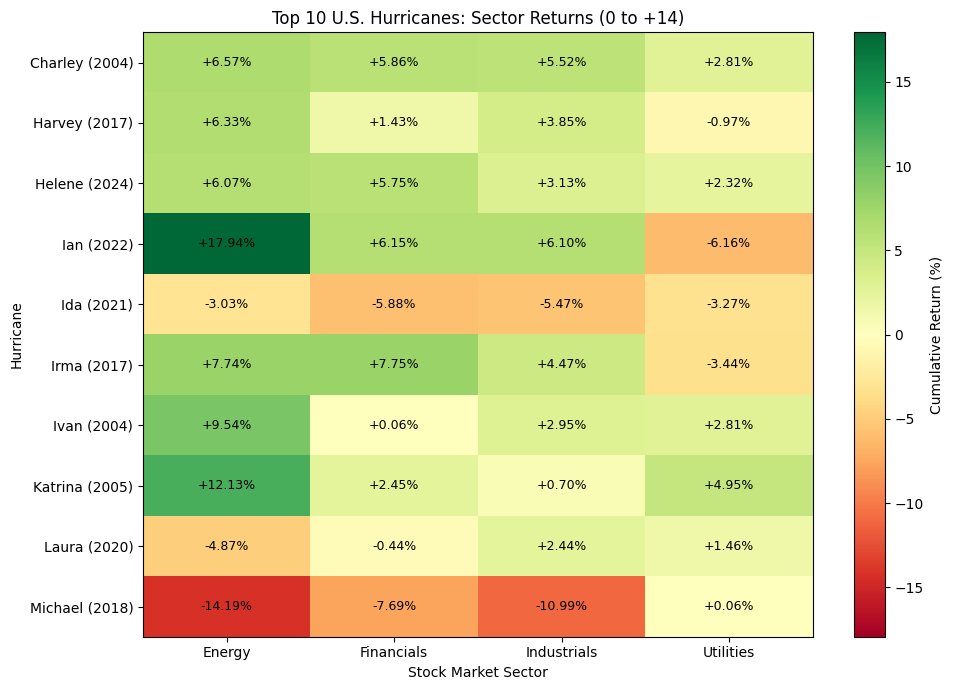

In [7]:
heatmap = (
    returns_df[returns_df["window"] == "0_to_14"]
    .pivot(
        index="hurricane",
        columns="sector",
        values="return_pct"
    )
)

heatmap = heatmap.rename(columns=sector_names)

fig, ax = plt.subplots(figsize=(10, 7))

values = heatmap.to_numpy()

limit = max(np.nanmax(np.abs(values)), 0.01)

im = ax.imshow(
    values,
    cmap="RdYlGn",
    vmin=-limit,
    vmax=limit,
    aspect="auto"
)

ax.set_xticks(range(len(heatmap.columns)))
ax.set_xticklabels(heatmap.columns)

ax.set_yticks(range(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)

for i in range(len(heatmap.index)):
    for j in range(len(heatmap.columns)):
        ax.text(
            j, i,
            f"{values[i, j]:+.2f}%",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(im, ax=ax, label="Cumulative Return (%)")

ax.set_title(
    "Top 10 U.S. Hurricanes: Sector Returns (0 to +14)"
)

ax.set_xlabel("Stock Market Sector")
ax.set_ylabel("Hurricane")

plt.tight_layout()
plt.show()

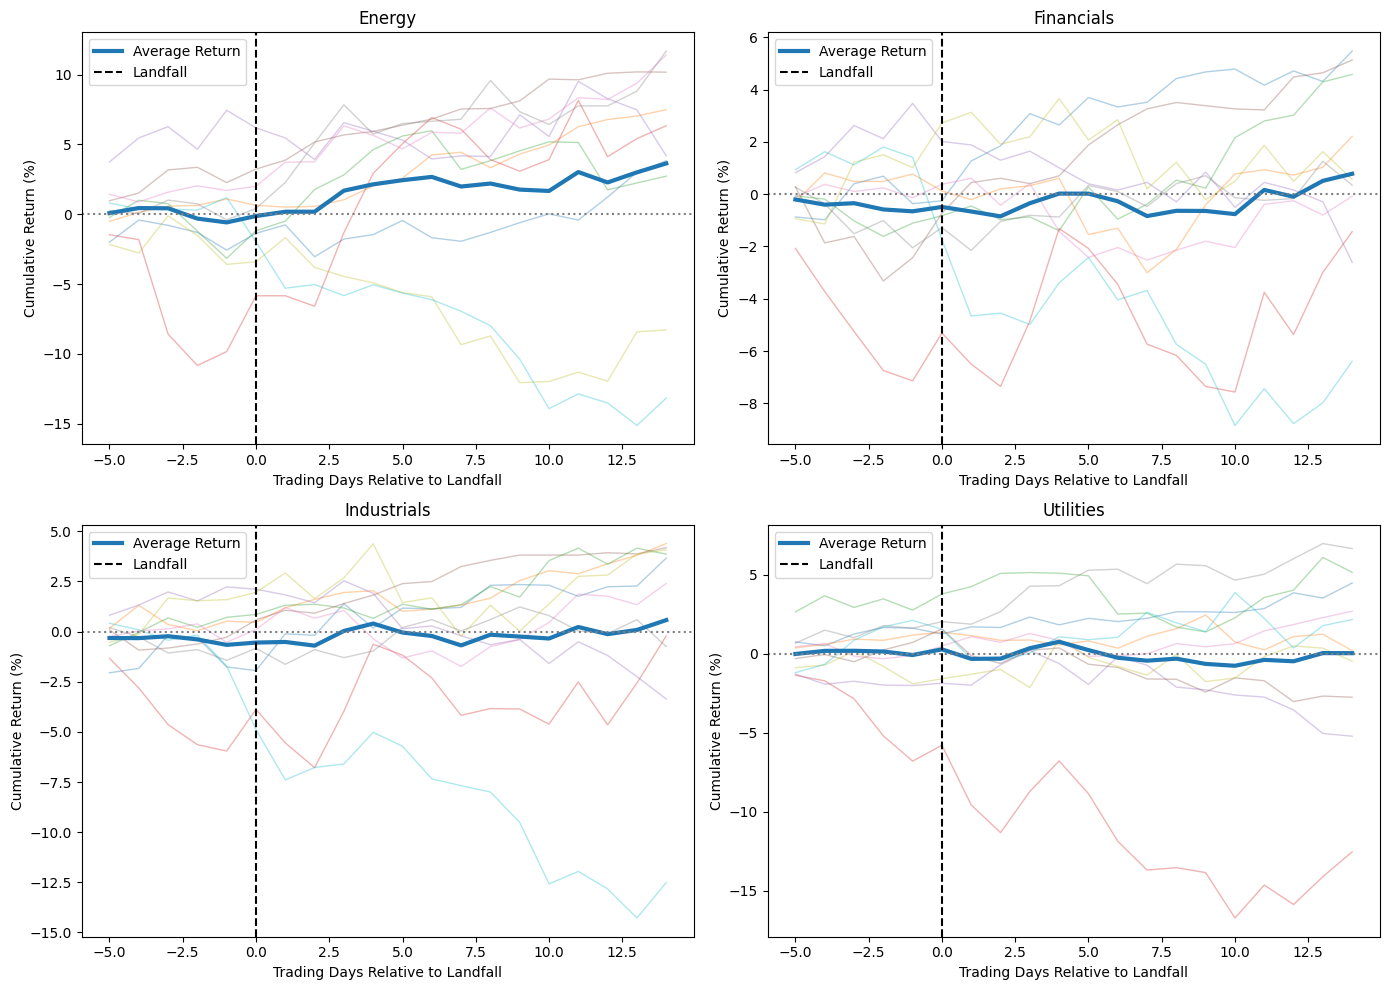

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, sector in zip(axes.flat, sectors):

    data = event_study[
        event_study["sector"] == sector
    ]

    for hurricane, group in data.groupby("hurricane"):
        ax.plot(
            group["relative_day"],
            group["cumulative_return"],
            linewidth=1,
            alpha=0.35
        )

    average = (
        data.groupby("relative_day")["cumulative_return"]
        .mean()
    )

    ax.plot(
        average.index,
        average.values,
        linewidth=3,
        label="Average Return"
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        label="Landfall"
    )

    ax.axhline(0, color="gray", linestyle=":")

    ax.set_title(sector_names[sector])
    ax.set_xlabel("Trading Days Relative to Landfall")
    ax.set_ylabel("Cumulative Return (%)")
    ax.legend()

plt.tight_layout()
plt.show()

In [9]:
summary = (
    returns_df
    .groupby(["sector", "window"])
    .agg(
        mean_return=("return_pct", "mean"),
        median_return=("return_pct", "median"),
        positive_count=(
            "return_pct",
            lambda x: (x > 0).sum()
        ),
        negative_count=(
            "return_pct",
            lambda x: (x < 0).sum()
        ),
        total_storms=("return_pct", "count")
    )
    .reset_index()
)

summary["sector"] = summary["sector"].replace(
    sector_names
)

display(summary)

,sector,window,mean_return,median_return,positive_count,negative_count,total_storms
0,Energy,0_to_1,0.843841,1.920369,7,3,10
1,Energy,0_to_14,4.422848,6.451802,7,3,10
2,Energy,0_to_5,3.223160,2.551648,7,3,10
3,Financials,0_to_1,0.019040,0.678244,6,4,10
4,Financials,0_to_14,1.543060,1.937671,7,3,10
5,Financials,0_to_5,0.749931,1.223039,6,4,10
6,Industrials,0_to_1,0.139902,0.630429,7,3,10
7,Industrials,0_to_14,1.271007,3.037323,8,2,10
8,Industrials,0_to_5,0.650109,0.567519,6,4,10
9,Utilities,0_to_1,-0.260593,0.055304,6,4,10


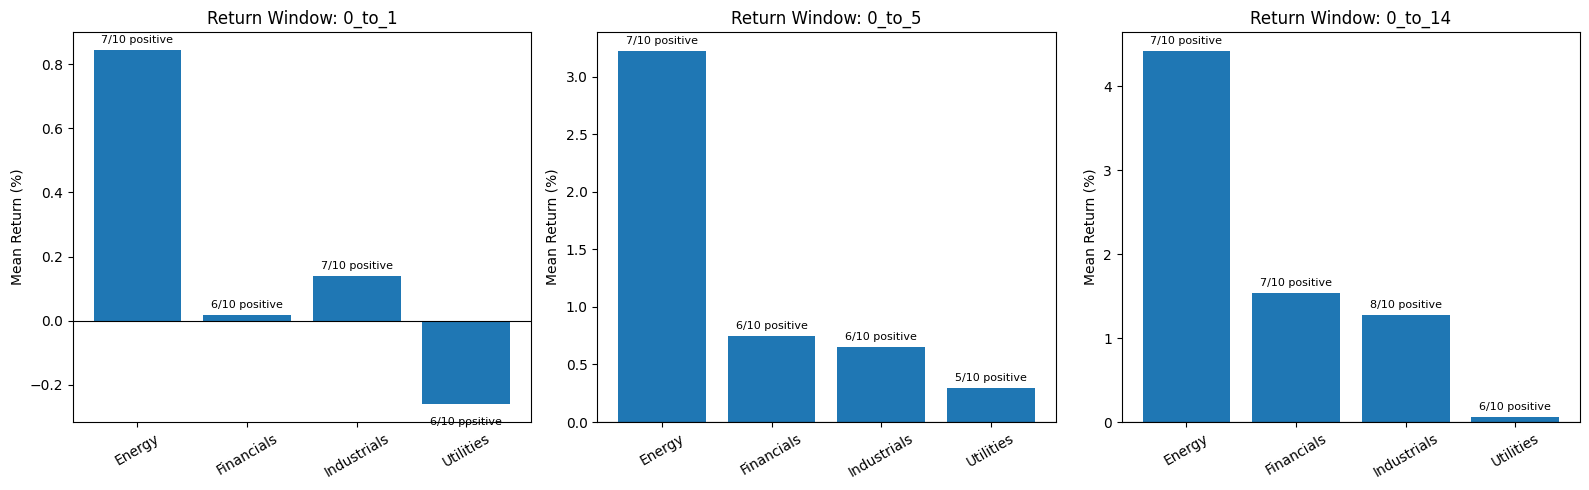

In [10]:
window_order = ["0_to_1", "0_to_5", "0_to_14"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, window_name in zip(axes, window_order):

    group = summary[
        summary["window"] == window_name
    ]

    bars = ax.bar(
        group["sector"],
        group["mean_return"]
    )

    for bar, (_, row) in zip(bars, group.iterrows()):

        height = bar.get_height()

        ax.annotate(
            f"{int(row['positive_count'])}/{int(row['total_storms'])} positive",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(
                0,
                5 if height >= 0 else -15
            ),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_title(f"Return Window: {window_name}")
    ax.set_ylabel("Mean Return (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [11]:
summary_without_2020 = (
    returns_df[returns_df["year"] != 2020]
    .groupby(["sector", "window"])["return_pct"]
    .mean()
    .reset_index(name="mean_return_without_2020")
)

comparison = (
    returns_df
    .groupby(["sector", "window"])["return_pct"]
    .mean()
    .reset_index(name="mean_return")
    .merge(
        summary_without_2020,
        on=["sector", "window"],
        how="left"
    )
)

comparison["sector"] = comparison["sector"].replace(
    sector_names
)

display(comparison)

,sector,window,mean_return,mean_return_without_2020
0,Energy,0_to_1,0.843841,0.716808
1,Energy,0_to_14,4.422848,5.455369
2,Energy,0_to_5,3.223160,3.814519
3,Financials,0_to_1,0.019040,-0.211446
4,Financials,0_to_14,1.543060,1.763716
5,Financials,0_to_5,0.749931,0.716958
6,Industrials,0_to_1,0.139902,0.009722
7,Industrials,0_to_14,1.271007,1.140778
8,Industrials,0_to_5,0.650109,0.738060
9,Utilities,0_to_1,-0.260593,-0.357679


In [12]:
from scipy import stats

def return_statistics(group):

    values = group["return_pct"].dropna()

    if len(values) < 2:
        return pd.Series({
            "mean_return": values.mean(),
            "p_value": np.nan,
            "positive_count": (values > 0).sum(),
            "n": len(values)
        })

    t_stat, p_value = stats.ttest_1samp(
        values,
        popmean=0
    )

    return pd.Series({
        "mean_return": values.mean(),
        "p_value": p_value,
        "positive_count": (values > 0).sum(),
        "n": len(values)
    })

significance = (
    returns_df
    .groupby(["sector", "window"])
    .apply(return_statistics, include_groups=False)
    .reset_index()
)

significance["sector"] = (
    significance["sector"].replace(sector_names)
)

display(significance.round(4))

,sector,window,mean_return,p_value,positive_count,n
0,Energy,0_to_1,0.8438,0.4104,7.0,10.0
1,Energy,0_to_14,4.4228,0.1669,7.0,10.0
2,Energy,0_to_5,3.2232,0.1532,7.0,10.0
3,Financials,0_to_1,0.0190,0.9813,6.0,10.0
4,Financials,0_to_14,1.5431,0.3726,7.0,10.0
5,Financials,0_to_5,0.7499,0.5007,6.0,10.0
6,Industrials,0_to_1,0.1399,0.8454,7.0,10.0
7,Industrials,0_to_14,1.2710,0.4753,8.0,10.0
8,Industrials,0_to_5,0.6501,0.4553,6.0,10.0
9,Utilities,0_to_1,-0.2606,0.5794,6.0,10.0
